# In-class work 5. Metrics: what a number says about a model

Industrial AI, KBTU. Goes with Lecture 5.

The data set is **AI4I 2020** again, the milling machine: 10 000 cycles, 339 failures, 3.4 %.
We know this machine well by now, so whatever surprises us today comes from the metrics.

The question is the one from In-class work 4: *will this cycle end in a failure?* Three models
answer it. We measure them in every way Lecture 5 lists and watch the ranking change:

1. why accuracy says nothing on fault data;
2. the confusion matrix, precision, recall, F1;
3. the threshold, and how it moves all of them;
4. ROC and precision-recall curves, and which of the two flatters a model on imbalanced data;
5. the threshold from money: the cost of a false alarm against a missed failure;
6. what the model misses, by failure mode;
7. how sure the number is: bootstrap intervals;
8. forecasting models: MAE, RMSE, MAPE, R², and a baseline that is hard to beat.

Run top to bottom with `Shift+Enter`. The whole notebook takes about 40 seconds.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

import sklearn

BLUE, ORANGE, RED, GREEN, PURPLE, GREY = (
    "#2a6f8e", "#e07b39", "#c0392b", "#4a8f5a", "#9b3f9b", "#9aa0a6")

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

KAGGLE = {
    'ai4i': 'stephanmatzka/predictive-maintenance-dataset-ai4i-2020',
}


def dataset_folder(name):
    """The folder with the files of a data set: the Kaggle copy (downloaded once, then cached),
    or data/<name>/ of the course repo if Kaggle is out of reach."""
    if KAGGLE[name]:
        try:
            import contextlib, io, logging, kagglehub
            logging.getLogger("kagglehub").setLevel(logging.ERROR)
            with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                folder = Path(kagglehub.dataset_download(KAGGLE[name]))
            print(f"{name}: Kaggle {KAGGLE[name]}")
            return folder
        except Exception as exc:
            print(f"Kaggle unavailable ({type(exc).__name__}), looking for data/{name}/")
    for root in [Path.cwd(), *Path.cwd().parents]:
        if (root / "data" / name).is_dir():
            return root / "data" / name
    raise FileNotFoundError(f"no data/{name}/ here or above; run data/fetch.py in the course repo")

print(" | ".join(f"{m} {sys.modules[m].__version__}" for m in
                 ("numpy", "pandas", "matplotlib", "scipy", "sklearn", "torch") if m in sys.modules))

numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2 | scipy 1.18.1 | sklearn 1.9.1


In [2]:
def load_ai4i():
    df = pd.read_csv(dataset_folder("ai4i") / "ai4i2020.csv", encoding="utf-8-sig")
    return df.rename(columns={
        "Product ID": "product", "Type": "type",
        "Air temperature [K]": "air", "Process temperature [K]": "process",
        "Rotational speed [rpm]": "rpm", "Torque [Nm]": "torque",
        "Tool wear [min]": "wear", "Machine failure": "failure"})


df = load_ai4i()
MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]
INPUTS = ["type", "air", "process", "rpm", "torque", "wear"]
X, y = df[INPUTS], df["failure"].to_numpy()
print(df.shape, "| failures:", y.sum(), f"({y.mean():.1%})")

ai4i: Kaggle stephanmatzka/predictive-maintenance-dataset-ai4i-2020
(10000, 14) | failures: 339 (3.4%)


---

# Part 1. Accuracy

## 1.1 Three pieces of data

Metrics are computed on data the model has not seen. Today we need a third piece on top of
train and test. The threshold and the choice between models are decisions too, and a decision
made on the test set turns the test result into a result of that decision. So:

| piece | share | what it is for |
|---|---|---|
| train | 60 % | fitting the models |
| validation | 20 % | choosing the threshold, comparing models |
| test | 20 % | one final measurement, touched once at the end |

Every piece keeps the 3.4 % failure rate (`stratify=y`).

In [3]:
from sklearn.model_selection import train_test_split

idx = np.arange(len(df))
tr, rest = train_test_split(idx, test_size=0.4, stratify=y, random_state=0)
va, te = train_test_split(rest, test_size=0.5, stratify=y[rest], random_state=0)
for name, part in [("train", tr), ("validation", va), ("test", te)]:
    print(f"{name:10s} {len(part):5d} cycles, {y[part].sum():3d} failures")

train       6000 cycles, 203 failures
validation  2000 cycles,  68 failures
test        2000 cycles,  68 failures


In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

lazy = DummyClassifier(strategy="most_frequent").fit(X.iloc[tr], y[tr])
lazy_says = lazy.predict(X.iloc[te])
print(f"'nothing ever fails': accuracy {accuracy_score(y[te], lazy_says):.3f}, "
      f"failures caught {lazy_says.sum()} of {y[te].sum()}")

'nothing ever fails': accuracy 0.966, failures caught 0 of 68


A model that always says "fine" is right 96.6 % of the time and has never caught a failure.
Accuracy is the share of correct answers, $(TP + TN)/n$, and on fault data the healthy majority
fills almost all of $n$. With a failure rate $\pi$, the lazy model scores $1 - \pi$ for free. Any
accuracy below that is worse than doing nothing, and an accuracy above it still says nothing
about failures.

From here on we print accuracy only to show how little it moves.

---

# Part 2. The confusion matrix

## 2.1 Three models

- **logistic regression**, plain;
- **logistic regression with `class_weight="balanced"`**: in the loss every failure counts as
  much as 28 healthy cycles (5797 / 203 in the train part), so the rare class cannot be
  ignored. This is the usual first fix for imbalance;
- **random forest**, 300 trees.

All three see the raw sensors and the product type. Each outputs a *score* between 0 and 1,
and `predict()` turns it into yes or no at the threshold 0.5.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

scaled = make_column_transformer((OneHotEncoder(), ["type"]), remainder=StandardScaler())
raw = make_column_transformer((OneHotEncoder(), ["type"]), remainder="passthrough")

logistic = LogisticRegression(max_iter=2000)
logistic_balanced = LogisticRegression(max_iter=2000, class_weight="balanced")
forest = RandomForestClassifier(300, random_state=0, n_jobs=-1)
models = {
    "logistic": make_pipeline(scaled, logistic),
    "logistic, balanced": make_pipeline(scaled, logistic_balanced),
    "random forest": make_pipeline(raw, forest),
}
score_va, score_te = {}, {}          # model name -> scores on validation and on test
for name, m in models.items():
    m.fit(X.iloc[tr], y[tr])
    score_va[name] = m.predict_proba(X.iloc[va])[:, 1]
    score_te[name] = m.predict_proba(X.iloc[te])[:, 1]
print("fitted:", list(models))

fitted: ['logistic', 'logistic, balanced', 'random forest']


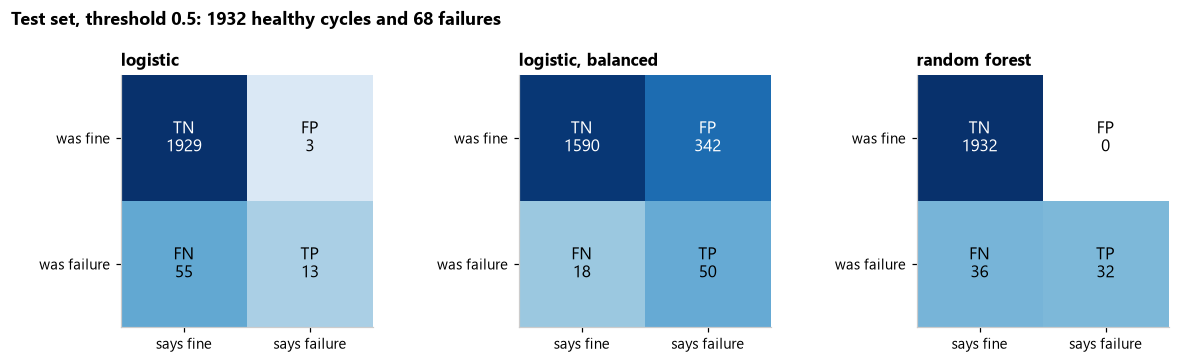

In [6]:
from sklearn.metrics import confusion_matrix

CELL_NAMES = ["TN", "FP", "FN", "TP"]          # row by row: (was fine, was failure)
log_colours = mpl.colors.LogNorm(vmin=1, vmax=2000)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, (name, s) in zip(axes, score_te.items()):
    cm = confusion_matrix(y[te], (s >= 0.5).astype(int))
    ax.imshow(cm, cmap="Blues", norm=log_colours)
    for (i, j), v in np.ndenumerate(cm):
        text_colour = "white" if v > 300 else "black"
        ax.text(j, i, f"{CELL_NAMES[2 * i + j]}\n{v}", ha="center", va="center",
                color=text_colour, fontsize=11)
    ax.set_xticks([0, 1], ["says fine", "says failure"])
    ax.set_yticks([0, 1], ["was fine", "was failure"])
    ax.grid(False)
    ax.set_title(name, fontsize=11)

n_healthy, n_failures = (y[te] == 0).sum(), y[te].sum()
title = f"Test set, threshold 0.5: {n_healthy} healthy cycles and {n_failures} failures"
fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

Four cells, and every metric below is a ratio of them:

- **TN**, true negative: healthy, and the model said so;
- **FP**, false positive, a **false alarm**: healthy, and the model stopped the machine;
- **FN**, false negative, a **missed failure**: the machine failed and the model said fine;
- **TP**, true positive: a failure caught.

$$\text{precision} = \frac{TP}{TP + FP} \qquad \text{recall} = \frac{TP}{TP + FN} \qquad F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$

In plant words, precision is how far the operator can trust an alarm, and recall is the share
of failures that get an alarm at all. The two look at different rows of the matrix: recall
stays inside the row of real failures, precision inside the column of alarms. The false-alarm
rate $FP / (FP + TN)$ is the share of healthy cycles stopped for nothing.

$F_1$ is the harmonic mean of precision and recall, and the harmonic mean is pulled towards the
smaller number. Write it as $F_1 = 2\,\min \cdot \max / (\min + \max)$: since
$\min + \max \ge \max$, it never exceeds $2 \min$. A model with recall 0.05 cannot reach an
$F_1$ above 0.10, however precise it is.

In [7]:
from sklearn.metrics import precision_score, recall_score, f1_score


def at_threshold(yt, s, t):
    p = (s >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, p).ravel()
    return {"accuracy": accuracy_score(yt, p),
            "precision": precision_score(yt, p, zero_division=0),
            "recall": recall_score(yt, p),
            "F1": f1_score(yt, p),
            "false-alarm rate": fp / (fp + tn),
            "alarms": int(tp + fp)}


pd.DataFrame({name: at_threshold(y[te], s, 0.5) for name, s in score_te.items()}).T

,accuracy,precision,recall,F1,false-alarm rate,alarms
logistic,0.971,0.812,0.191,0.310,0.002,16.000
"logistic, balanced",0.820,0.128,0.735,0.217,0.177,392.000
random forest,0.982,1.000,0.471,0.640,0.000,32.000


The accuracies are 0.971, 0.820 and 0.982. The balanced logistic regression has the
**lowest** accuracy and the **highest** recall: it catches 50 of 68 failures, and to do it it
stops 342 healthy cycles, so only one alarm in eight is real. The plain logistic regression is
the opposite: 16 alarms, 13 of them real, and 55 failures missed.

Which one is better? The models cannot answer that. It depends on what a false alarm and a
missed failure cost, and we come to that in Part 5.

---

# Part 3. The threshold

## 3.1 Nothing forces 0.5

`predict()` uses 0.5, but the score is the model's output and the threshold is **our**
decision. Lower it and the model alarms more: recall goes up, precision goes down. Here is the
forest on the validation set, with the threshold moving from 0 to 1.

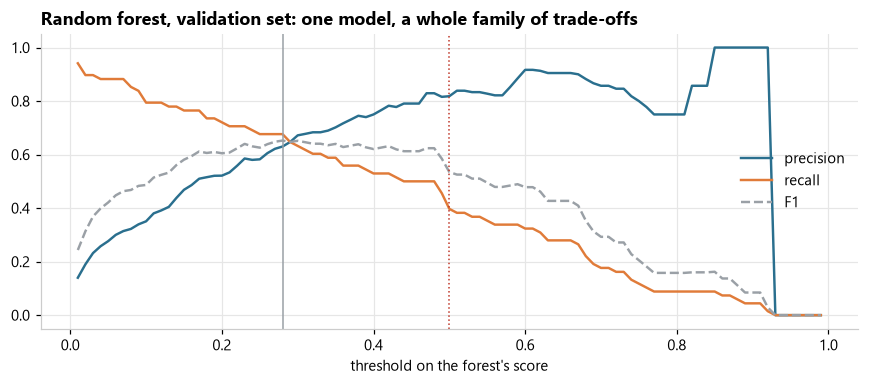

best F1 0.652 at threshold 0.28;  at 0.5: F1 0.535


In [8]:
ts = np.linspace(0.01, 0.99, 99)
s = score_va["random forest"]
rows = [at_threshold(y[va], s, t) for t in ts]
curve = pd.DataFrame(rows, index=ts)[["precision", "recall", "F1"]]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curve.index, curve["precision"], color=BLUE, label="precision")
ax.plot(curve.index, curve["recall"], color=ORANGE, label="recall")
ax.plot(curve.index, curve["F1"], color=GREY, ls="--", label="F1")
best = curve["F1"].idxmax()
ax.axvline(best, color=GREY, lw=1)
ax.axvline(0.5, color=RED, lw=1, ls=":")
ax.legend(loc="center right")
ax.set(xlabel="threshold on the forest's score",
       title="Random forest, validation set: one model, a whole family of trade-offs")
fig.tight_layout()
plt.show()

best_f1, f1_at_half = curve["F1"].max(), curve.loc[0.5, "F1"]
print(f"best F1 {best_f1:.3f} at threshold {best:.2f};  at 0.5: F1 {f1_at_half:.3f}")

At 0.5 the forest is cautious: almost every alarm is right, and half the failures pass. Its
best F1 on validation is 0.65 at a threshold of 0.28, against 0.54 at 0.5. There is nothing
special about 0.5. It is the right threshold only when a false alarm and a miss cost the same
and the scores are true probabilities, and usually neither holds.

Recall can only fall as the threshold rises, because every alarm at a higher threshold is also
an alarm at a lower one. Precision has no such rule: it is a ratio, and its numerator and
denominator both shrink, so the curve is ragged where few cycles are flagged.

So a single precision or recall means little without its threshold next to it. To compare
models without picking a threshold, we need curves.

---

# Part 4. ROC and precision-recall curves

## 4.1 Every threshold at once

Move the threshold from 1 down to 0 and record two pairs of numbers at every step.

- **ROC curve**: recall (the true positive rate) against the false-alarm rate. The area under
  it, **ROC-AUC**, has a meaning of its own. Take a random failure and a random healthy cycle;
  ROC-AUC is the probability that the failure gets the higher score. A coin gets 0.5, a perfect
  ranking 1.
- **PR curve**: precision against recall. Its area, **average precision** (AP, or PR-AUC),
  starts from the failure rate. A model that scores at random flags failures and healthy cycles
  in their natural proportion, so its precision is $\pi$ at every threshold: a coin has
  AP = 0.034 here, not 0.5.

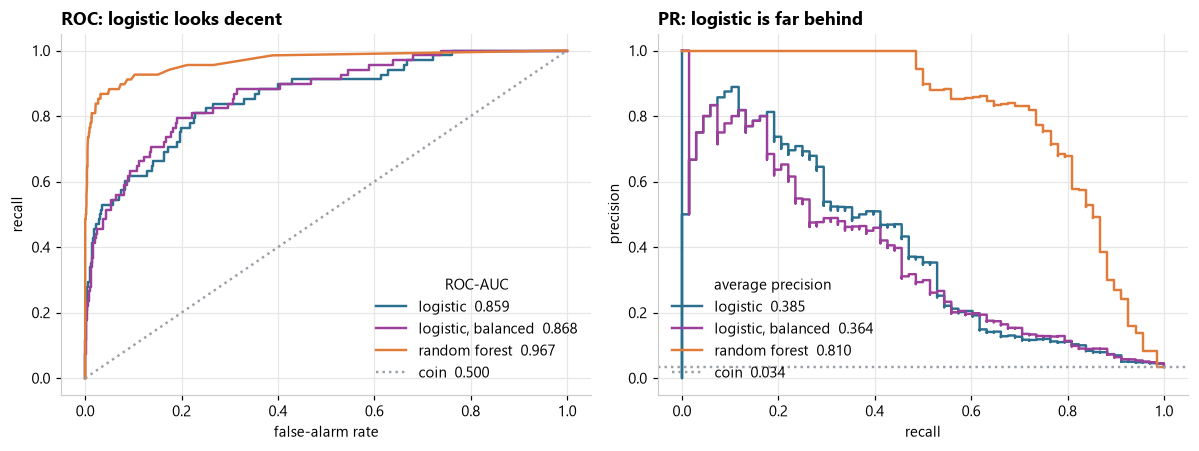

In [9]:
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.metrics import roc_auc_score, average_precision_score

colors = {"logistic": BLUE, "logistic, balanced": PURPLE, "random forest": ORANGE}
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.2))
for name, s in score_te.items():
    fpr, tpr, _ = roc_curve(y[te], s)
    auc = roc_auc_score(y[te], s)
    ax_roc.plot(fpr, tpr, color=colors[name], label=f"{name}  {auc:.3f}")

    prec, rec, _ = precision_recall_curve(y[te], s)
    ap = average_precision_score(y[te], s)
    ax_pr.step(rec, prec, where="post", color=colors[name], label=f"{name}  {ap:.3f}")

ax_roc.plot([0, 1], [0, 1], color=GREY, ls=":", label="coin  0.500")
ax_pr.axhline(y[te].mean(), color=GREY, ls=":", label=f"coin  {y[te].mean():.3f}")
ax_roc.set(xlabel="false-alarm rate", ylabel="recall", title="ROC: logistic looks decent")
ax_pr.set(xlabel="recall", ylabel="precision", title="PR: logistic is far behind")
ax_roc.legend(title="ROC-AUC", loc="lower right")
ax_pr.legend(title="average precision", loc="lower left")
fig.tight_layout()
plt.show()

**Why is the area under a curve equal to a probability about pairs?**

<details><summary>Answer</summary>

Sort the healthy cycles by score and lower the threshold past them one by one. Each one moves
the ROC curve right by $1/n_0$, where $n_0$ is the number of healthy cycles. The strip it adds
has the height of the recall at that moment: the share of failures that score above this
healthy cycle. Add up the strips:

$$\text{AUC} = \frac{1}{n_0 n_1}\sum_{\text{healthy } j}\ \sum_{\text{failure } i}
\Big(\mathbb{1}[s_i > s_j] + \tfrac12\,\mathbb{1}[s_i = s_j]\Big),$$

with $n_1$ failures. The double sum is the Mann–Whitney $U$ statistic, so
$\text{AUC} = U / (n_0 n_1)$: the share of (failure, healthy) pairs that the model orders
correctly, a tie counting half. The cell below checks it on the forest's test scores.

</details>

In [10]:
from scipy.stats import mannwhitneyu

rf_scores = score_te["random forest"]
fail_scores = rf_scores[y[te] == 1]
healthy_scores = rf_scores[y[te] == 0]

# U counts the pairs where the failure scores higher, a tie counting half
u = mannwhitneyu(fail_scores, healthy_scores).statistic
n_pairs = len(fail_scores) * len(healthy_scores)

print(f"(failure, healthy) pairs   {n_pairs}")
print(f"U / pairs                  {u / n_pairs:.6f}")
print(f"roc_auc_score              {roc_auc_score(y[te], rf_scores):.6f}")

(failure, healthy) pairs   131376
U / pairs                  0.967308
roc_auc_score              0.967308


On the ROC plot the logistic regressions look respectable, 0.86–0.87 against the forest's
0.97. On the PR plot they get 0.36–0.39 against 0.81. Same models, same test set.

The two curves divide by different things. Write precision through the rates, with
$\pi$ the failure rate:

$$\text{precision} = \frac{\text{recall}\cdot \pi}{\text{recall}\cdot\pi + \text{FPR}\cdot(1-\pi)}$$

With $\pi = 0.034$ the false-alarm rate is multiplied by 28 times more cycles than the recall.
A false-alarm rate of 5 % is 97 of the 1932 healthy test cycles, a thin slice on the ROC plot.
On the PR plot those 97 false alarms sit next to at most 68 true ones, and precision collapses.

## 4.2 An experiment: the same model on a healthier plant

Keep the test failures and repeat every healthy test cycle ten times. The model and its scores
stay the same; only the failure rate drops from 3.4 % to 0.35 %.

In [11]:
healthy = y[te] == 0
y10 = np.r_[y[te], np.zeros(9 * healthy.sum(), int)]
diluted = {}                        # model name -> the four numbers
for name, s in score_te.items():
    s10 = np.r_[s, np.tile(s[healthy], 9)]
    diluted[name] = {
        "ROC-AUC": roc_auc_score(y[te], s),
        "ROC-AUC, 10x healthy": roc_auc_score(y10, s10),
        "AP": average_precision_score(y[te], s),
        "AP, 10x healthy": average_precision_score(y10, s10),
    }
pd.DataFrame(diluted).T

,ROC-AUC,"ROC-AUC, 10x healthy",AP,"AP, 10x healthy"
logistic,0.859,0.859,0.385,0.100
"logistic, balanced",0.868,0.868,0.364,0.095
random forest,0.967,0.967,0.810,0.607


ROC-AUC does not move at all. It compares failures with healthy cycles pair by pair, and ten
copies of a healthy cycle add ten copies of the same pairs, so every share stays the same. In
the formula above, recall and the false-alarm rate at each threshold are unchanged too. Only
$\pi$ fell, and precision falls with it: AP drops for the forest from 0.81 to 0.61, for the
logistic regression from 0.39 to 0.10. An operator in the healthier plant really does get far
more false alarms for every true one. AP shows that and ROC-AUC hides it.

A rule for fault data: **report the PR curve and AP**, with the failure rate written next to
it. Use ROC-AUC to compare models on the same data, never to promise anything to an operator.

---

# Part 5. The threshold from money

## 5.1 Costs, and the threshold they imply

Suppose that on this machine

- a **false alarm** costs 1 unit: the machine stops, a technician looks, finds nothing,
  restarts;
- a **missed failure** costs 20 units: a broken tool, a scrapped part, an hour of downtime.

If the score $p$ is an honest probability of failure, then alarming costs $(1 - p) \cdot C_{FP}$
on average (we pay when the cycle was healthy) and staying silent costs $p \cdot C_{FN}$. Alarm
when silence is dearer:

$$p \cdot C_{FN} > (1-p) \cdot C_{FP} \quad \Longleftrightarrow \quad p > t^* = \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{1}{21} = 0.048$$

The threshold is the point where the two expected costs are equal. A miss twenty times dearer
than a false alarm moves it from 0.5 down to 1/21: we stop the machine already at a 5 % chance
of failure.

The derivation has one condition: **the score must be a calibrated probability.** We check
that condition in 5.3. First the direct way: count the money on the validation set for every
threshold and take the cheapest.

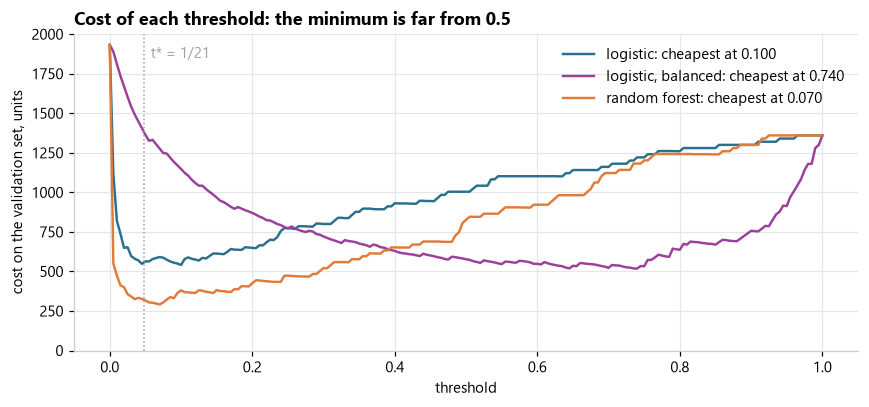

In [12]:
C_FP, C_FN = 1, 20
T_STAR = C_FP / (C_FP + C_FN)


def cost(yt, s, t):
    alarm = s >= t
    return C_FP * (alarm & (yt == 0)).sum() + C_FN * (~alarm & (yt == 1)).sum()


grid = np.linspace(0, 1, 201)
chosen = {}                       # model name -> cheapest threshold on validation
fig, ax = plt.subplots(figsize=(8, 3.8))
for name, s in score_va.items():
    c = np.array([cost(y[va], s, t) for t in grid])
    chosen[name] = grid[c.argmin()]
    ax.plot(grid, c, color=colors[name], label=f"{name}: cheapest at {chosen[name]:.3f}")
ax.axvline(T_STAR, color=GREY, ls=":", lw=1)
ax.text(T_STAR + 0.01, 1850, "t* = 1/21", color=GREY)
ax.set(xlabel="threshold", ylabel="cost on the validation set, units", ylim=(0, 2000),
       title="Cost of each threshold: the minimum is far from 0.5")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

## 5.2 The test set, once

The thresholds are fixed now. Only at this point do we open the test set, and we compare with
two policies that need no model at all: never stop the machine, and inspect every cycle.

In [13]:
policies = {"never alarm": ("-", C_FN * y[te].sum()),
            "inspect every cycle": ("-", C_FP * (y[te] == 0).sum())}
for name, s in score_te.items():
    thresholds = {"0.5": 0.5, "t* = 1/21": T_STAR, "cheapest on validation": chosen[name]}
    for label, t in thresholds.items():
        policies[f"{name}, {label}"] = (f"{t:.3f}", cost(y[te], s, t))
table = pd.DataFrame(policies, index=["threshold", "cost"]).T
table["per 1000 cycles"] = table["cost"].astype(float) / len(te) * 1000
table

,threshold,cost,per 1000 cycles
never alarm,-,1360,680.000
inspect every cycle,-,1932,966.000
"logistic, 0.5",0.500,1103,551.500
"logistic, t* = 1/21",0.048,748,374.000
"logistic, cheapest on validation",0.100,747,373.500
"logistic, balanced, 0.5",0.500,702,351.000
"logistic, balanced, t* = 1/21",0.048,1404,702.000
"logistic, balanced, cheapest on validation",0.740,734,367.000
"random forest, 0.5",0.500,720,360.000
"random forest, t* = 1/21",0.048,294,147.000


Read the table from the top.

- Doing nothing costs 1360 units on these 2000 cycles, and inspecting everything costs 1932.
  **Any model must beat 1360**, or it should not be installed.
- The forest at 0.5 costs 720. At its validation threshold it costs 266, a fifth of doing
  nothing. The model is the same; the threshold alone cut the cost by 63 %.
- The plain logistic regression at $t^* = 1/21$ costs 748, and the cheapest threshold on
  validation gives almost the same, 747. Here the formula worked.
- The **balanced** logistic regression at $t^*$ costs 1404, worse than doing nothing. Here the
  formula failed, and the next cell shows why.

## 5.3 Calibration: is a score of 0.3 really a 30 % chance?

Sort the validation cycles by score into ten bins of equal size and compare, in each bin, the
mean score with the share of real failures. A calibrated model sits on the diagonal: among the
cycles it scores near 0.3, three in ten fail.

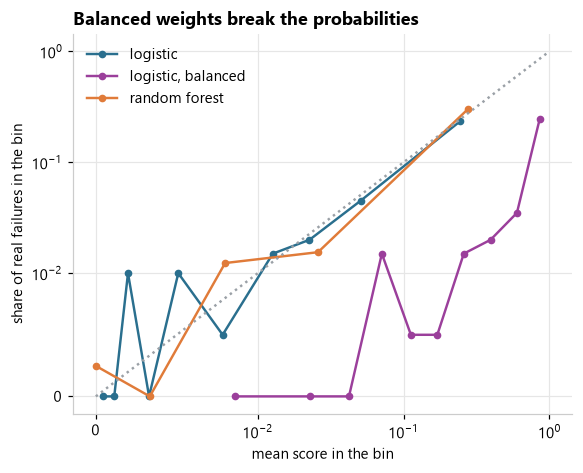

In [14]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(5.4, 4.4))
for name, s in score_va.items():
    frac, mean = calibration_curve(y[va], s, n_bins=10, strategy="quantile")
    ax.plot(mean, frac, "o-", color=colors[name], label=name, ms=4)
ax.plot([0, 1], [0, 1], color=GREY, ls=":")
ax.set_xscale("symlog", linthresh=0.01)
ax.set_yscale("symlog", linthresh=0.01)
ax.set(xlabel="mean score in the bin", ylabel="share of real failures in the bin",
       title="Balanced weights break the probabilities")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

The plain logistic regression and the forest follow the diagonal. The balanced one lies far
from it: in its top bin the mean score is 0.86 and the real failure rate is 0.25. Weighting
each failure 28 times is the same as telling the model that failures are 28 times more common
than they are. The log-loss is minimised by the probability of the data it is shown, so the
scores learned that inflated rate.

That leaves two honest routes to a threshold:

1. a calibrated model, and $t^* = C_{FP} / (C_{FP} + C_{FN})$ straight from the costs;
2. any model, and the threshold chosen by counting the cost on a **validation** set.

`class_weight="balanced"` is fine for ranking: look at its ROC-AUC and AP, no worse than those
of the plain model. Its score cannot be read as a probability.

---

# Part 6. What the model misses

A total cost hides *which* failures get through. Here is the forest at its chosen threshold,
by failure mode:

In [15]:
t_rf = chosen["random forest"]
alarm = score_te["random forest"] >= t_rf
test = df.iloc[te]
groups = {mode: (test[mode] == 1).to_numpy() for mode in MODES}
failed = (test["failure"] == 1).to_numpy()
no_mode = (test[MODES].sum(axis=1) == 0).to_numpy()
groups["no mode recorded"] = failed & no_mode

out = pd.DataFrame({"failures in test": {g: m.sum() for g, m in groups.items()},
                    "caught": {g: alarm[m].sum() for g, m in groups.items()}})
out["recall"] = out["caught"] / out["failures in test"]

false_alarms = int((alarm & (y[te] == 0)).sum())
print(f"threshold {t_rf:.3f}, false alarms {false_alarms}")
out

threshold 0.070, false alarms 106


,failures in test,caught,recall
TWF,8,1,0.125
HDF,24,24,1.000
PWF,18,17,0.944
OSF,21,21,1.000
RNF,4,0,0.000
no mode recorded,1,1,1.000


Heat, power and overstrain failures are caught almost completely. Tool wear failures and
random failures are not, as In-class work 4 predicted: no sensor says *in which* cycle the tool
breaks.

This is the table an engineer wants. One overall recall would hide a failure mode that is
almost never caught. "HDF 24 of 24, TWF 1 of 8" says what the model handles and what to hand
over to maintenance planning.

---

# Part 7. How sure is the number?

The test set has 68 failures. Swap a few of them for others and the AP changes. By how much?
The **bootstrap** answers without new data: draw 2000 cycles from the test set *with
replacement*, compute the metric, repeat 1000 times, and look at the spread.

The idea: the test set is our best picture of the population, so resampling it imitates
drawing new test sets. With 68 failures the scale of the noise is easy to guess. The forest's
recall at its threshold is 60 of 68, a share $\hat p = 0.88$, and a share of $n$ items scatters
by about $\sqrt{\hat p(1-\hat p)/n} = \sqrt{0.88 \cdot 0.12 / 68} \approx 0.04$.

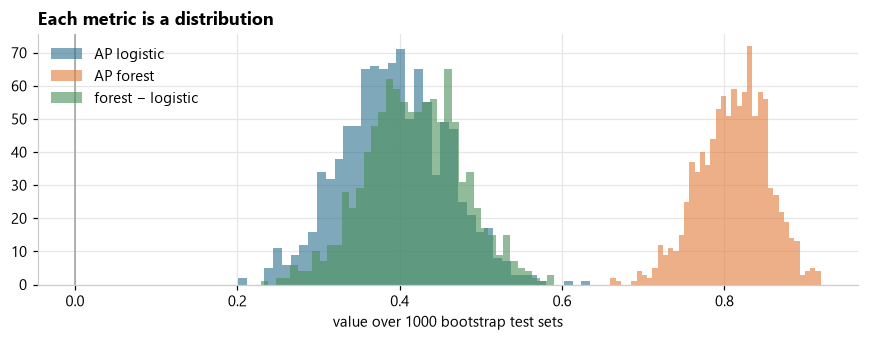

                   2.5 %  median  97.5 %
AP forest          0.723   0.814   0.887
AP logistic        0.267   0.391   0.517
recall forest      0.798   0.884   0.953
forest − logistic  0.299   0.417   0.533


In [16]:
rng = np.random.default_rng(0)
yt, s_rf, s_lr = y[te], score_te["random forest"], score_te["logistic"]
boot = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))      # a test set drawn with replacement
    caught = (s_rf[i] >= t_rf) & (yt[i] == 1)
    boot.append({"AP forest": average_precision_score(yt[i], s_rf[i]),
                 "AP logistic": average_precision_score(yt[i], s_lr[i]),
                 "recall forest": caught.sum() / yt[i].sum()})
boot = pd.DataFrame(boot)
boot["forest − logistic"] = boot["AP forest"] - boot["AP logistic"]

fig, ax = plt.subplots(figsize=(8, 3.2))
hist_colours = {"AP logistic": BLUE, "AP forest": ORANGE, "forest − logistic": GREEN}
for col, c in hist_colours.items():
    ax.hist(boot[col], bins=40, color=c, alpha=0.6, label=col)
ax.axvline(0, color=GREY, lw=1)
ax.set(xlabel="value over 1000 bootstrap test sets",
       title="Each metric is a distribution")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

intervals = boot.quantile([0.025, 0.5, 0.975]).T
print(intervals.rename(columns={0.025: "2.5 %", 0.5: "median", 0.975: "97.5 %"}))

The forest's AP lies somewhere between about 0.72 and 0.89. Its recall at the chosen threshold
runs from 0.80 to 0.95, two of the standard errors guessed above on either side. With 68
failures the second decimal of any metric is noise.

The useful line is the **difference**, computed on the *same* bootstrap sample for both models
(a paired comparison). Both models meet the same easy and hard failures in each resample, so
much of the noise cancels in the difference. Its interval stays well above zero: the forest is
better, and luck does not explain it. When the interval of a difference contains zero, the
honest report is "we cannot tell these two models apart on this test set".

---

# Part 8. Forecasting models

## 8.1 Errors in the units of the answer

Lecture 5 also covers models that predict a **number**: a temperature, a load, a remaining
life. Their metrics measure the size of the error $e_i = y_i - \hat y_i$:

| metric | formula | in words |
|---|---|---|
| MAE | $\frac{1}{n}\sum \lvert e_i \rvert$ | typical error, in the units of $y$ |
| RMSE | $\sqrt{\frac{1}{n}\sum e_i^2}$ | like MAE, but large errors weigh more |
| MAPE | $\frac{100\%}{n}\sum \lvert e_i / y_i \rvert$ | error as a share of the value |
| R² | $1 - \sum e_i^2 / \sum (y_i - \bar y)^2$ | share of the variance explained; 1 is perfect, 0 is "predict the mean of the test period" |
| MASE | MAE / MAE of the naive forecast | below 1: better than repeating the last value |

RMSE is never below MAE, and the gap grows with the size of the rare large errors, because
squaring weighs an error of 2 four times as much as an error of 1. R² compares the model with
one particular baseline, the mean of the data being scored. If the signal moves a lot over the
test period, that baseline is poor and any forecast that follows the signal scores high.

The task: predict the **air temperature 10 cycles ahead** from the last 20 readings. Train on
the first 7000 cycles and test on the last 3000, in time order.

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

air = df["air"].to_numpy()
H, L, CUT = 10, 20, 7000           # horizon, lags, first test cycle
t_now = np.arange(L - 1, len(air) - H)             # the cycles at which we forecast
# the last 20 readings, newest first
lags = np.column_stack([air[t_now - k] for k in range(L)])
target = air[t_now + H]
train_f, test_f = t_now < CUT, t_now >= CUT

last = air[t_now]
# the linear model predicts the change from the last reading, from the lags relative to it
lags_rel = lags - last[:, None]
change = target - last
reg = LinearRegression().fit(lags_rel[train_f], change[train_f])
forecasts = {
    "naive: the last reading": last,
    "mean of the last 20": lags.mean(axis=1),
    "linear model on 20 lags": last + reg.predict(lags_rel),
    "mean of the training period": np.full(len(t_now), target[train_f].mean()),
}

yt_f = target[test_f]
mae_naive = mean_absolute_error(yt_f, last[test_f])
errors = {}                                    # forecast name -> its metrics
for name, f in forecasts.items():
    e = f[test_f]
    miss = yt_f - e
    errors[name] = {"MAE, K": mean_absolute_error(yt_f, e),
                    "RMSE, K": np.sqrt(mean_squared_error(yt_f, e)),
                    "MAPE in K, %": 100 * np.mean(np.abs(miss / yt_f)),
                    "MAPE in °C, %": 100 * np.mean(np.abs(miss / (yt_f - 273.15))),
                    "R²": r2_score(yt_f, e),
                    "MASE": mean_absolute_error(yt_f, e) / mae_naive}
pd.DataFrame(errors).T

,"MAE, K","RMSE, K","MAPE in K, %","MAPE in °C, %",R²,MASE
naive: the last reading,0.143,0.183,0.048,0.553,0.976,1.000
mean of the last 20,0.174,0.223,0.058,0.677,0.965,1.222
linear model on 20 lags,0.144,0.183,0.048,0.560,0.976,1.011
mean of the training period,1.466,1.823,0.492,5.865,-1.341,10.270


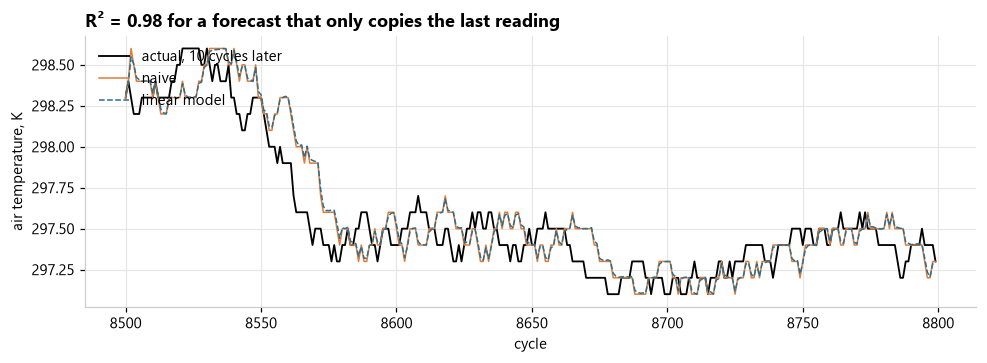

In [18]:
k = slice(1500, 1800)
cycles = t_now[test_f][k]
naive = forecasts["naive: the last reading"][test_f][k]
linear = forecasts["linear model on 20 lags"][test_f][k]
r2_naive = errors["naive: the last reading"]["R²"]

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(cycles, yt_f[k], color="black", lw=1.2, label="actual, 10 cycles later")
ax.plot(cycles, naive, color=ORANGE, lw=1, label="naive")
ax.plot(cycles, linear, color=BLUE, lw=1, ls="--", label="linear model")
ax.set(xlabel="cycle", ylabel="air temperature, K",
       title=f"R² = {r2_naive:.2f} for a forecast that only copies the last reading")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

The table holds four lessons.

1. **An R² of 0.98 means little on its own.** The naive forecast, "10 cycles from now it will
   be what it is now", gets it. Over 3000 cycles the air temperature wanders by a few kelvin,
   while in 10 cycles it moves by a fraction of one. The denominator of R² is the wide wander,
   the numerator the small step, so their ratio is close to zero and R² close to one.
2. **A model has to beat the naive forecast, not zero.** The linear model on 20 lags has
   MASE 1.01: it learned to copy the last reading. The air temperature here behaves like a
   random walk, and for a random walk the best forecast of any future value is the present
   one; the past adds nothing. Without the naive row, "RMSE 0.18 K, R² 0.98" would look like a
   success.
3. **MAPE depends on where zero is.** The same errors are 0.05 % in kelvin and 0.55 % in
   degrees Celsius, because the denominator $y_i$ is 300 in one scale and 27 in the other.
   Neither number is wrong, and neither can be compared with a MAPE from another plant. Use
   MAPE only for quantities with a real zero (flow, power, a count), and never near zero.
4. **The training mean has a negative R².** The test period is warmer than the training
   period, so the old mean is worse than the test period's own mean, which is the baseline of
   R². A negative R² is allowed. It means "worse than a constant".

---

## Further reading

- Conformal prediction wraps any trained classifier. From the scores of held-out failures it
  picks a threshold that misses, on average, at most a chosen share $\alpha$ of new failures,
  provided the new ones are exchangeable with the held-out ones. On a plant this gives an alarm
  rule with a known miss rate, and the model's scores need not be true probabilities. A
  readable start is A. N. Angelopoulos and S. Bates, "A Gentle Introduction to Conformal
  Prediction and Distribution-Free Uncertainty Quantification" (2021).

---

## Questions to think about

1. A colleague reports "our failure detector has 97 % accuracy". Which two numbers do you ask
   for before you believe anything?
2. The forest at 0.5 had precision 1.00. Why is that not a reason to keep 0.5?
3. Costs change: a missed failure now costs 5 units instead of 20. Which threshold does the
   formula give, and which model would you trust to use it?
4. The balanced logistic regression is a poor probability and a decent ranking. Name a
   situation where a ranking is all you need.
5. Why is the forecasting test set cut by time (first 7000, last 3000) instead of drawn at
   random, as in Part 1?

**Next: Practice 3** does the same on a much harder data set, a semiconductor line where one
wafer lot in fifteen fails and 590 sensors barely know why.